# CORRECTED NOTEBOOK -- re-run with *Kernel > Restart & Run All*

Only these lines were changed (everything else is identical to the original):

- cell 28: GlcMethylKaempferol SMILES with defined beta-D-glucoside stereochemistry

All outputs were cleared because the scores of the corrected compounds change.

# Molecular docking -- Lamium_amplexicaule vs AChE (1EVE)

cleanup

In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1EVE',type='pdb1')
cmd.select(name='Prot',selection='polymer.protein')
cmd.save(filename='1EVE_clean.pdb',format='pdb',selection='Prot',state=1)

# 1EVE's native ligand is E2020 (donepezil), PDB ligand code E20. Unlike
# COX-2/5IKQ, 1EVE is a monomer (not a homodimer), so no chain-specific
# selection is needed -- but state=1 is kept for consistency/safety.
cmd.select(name='NativeLig', selection='resn E20')
_natlig_model = cmd.get_model('NativeLig', state=1)
_natlig_resns = sorted(set((a.resn, a.chain) for a in _natlig_model.atom))
print("Native ligand residue(s) found (resn, chain):", _natlig_resns, "| atom count:", len(_natlig_model.atom))
cmd.save(filename='1EVE_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand residue(s) found (resn, chain): [('E20', 'A')] | atom count: 28


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'1EVE_clean.pdb'}

os.rename('pro.pdb','1EVE_clean_H.pdb')


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1EVE_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1EVE_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [7]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1EVE_clean_H.pdb'} -o {'1EVE_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment", use this fallback:
# import subprocess
# r = subprocess.run(["obabel", "1EVE_clean_H.pdb", "-O", "1EVE_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)


set verbose to  True
set receptor_filename to  1EVE_clean_H.pdb
set outputfilename to  1EVE_clean_H.pdbqt
read  1EVE_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  1EVE_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None


In [8]:
fix_protein(filename='1EVE_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1EVE_clean_H_fix.pdb')


## 7. Screening PHYTO compounds (Lamium_amplexicaule) against AChE (1EVE)

Reuses the receptor (`1EVE_clean_H.pdb`/`.pdbqt`) and the docking box
(native ligand E20/donepezil, `state=1`) prepared above. Each compound
docked in its own cell with its own uniquely-named variables, seed pinned
at 42. Source: Laggoune et al. 2008 (Djebel El-Ouahch, Constantine).
SMILES verified against PubChem: Chrysoeriol (CID 5280666), Stigmasterol
(CID 5280794).

**Note on Stigmasterol**: this is the same compound that scored
anomalously weak (-3 kcal/mol) against COX-2/5IKQ, which turned out to be
a genuine structure-specific steric mismatch (confirmed by redocking
against 3NTG, which gave -9.8 kcal/mol) -- not a pipeline bug. AChE's
binding gorge is known to accommodate a large co-crystallized ligand
(donepezil) comfortably, so a similar mismatch is less likely here, but
if Stigmasterol's score comes back unexpectedly weak or its top poses
collapse in quality after pose 1-2 (check the full `energies_Stigmasterol`
printout, not just the best value), the same exhaustiveness/box-widening
fix used for COX-2 may be needed -- see the commented-out block in 7.3.

In [9]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1EVE_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1EVE_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1EVE_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand E20, `state=1`)

In [10]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': 2.0225000381469727, 'center_y': 63.295000076293945, 'center_z': 67.0615005493164} 
 {'size_x': 16.913000106811523, 'size_y': 21.296001434326172, 'size_z': 21.733001708984375}


In [11]:
import subprocess
from rdkit.Chem.rdMolAlign import GetBestRMS

REDOCK_DIR = os.path.join(DOCKING_DIR, "redocking_validation")
os.makedirs(REDOCK_DIR, exist_ok=True)

PDB_CODE = os.path.basename(RECEPTOR_PDB).split('_')[0]

# 1) Prepare the NATIVE ligand for docking -- from its crystal geometry
#    (NATIVE_LIG, the mol2 extracted from the PDB), NOT a fresh SMILES
#    conformer. Uses the same prepare_ligand tool as the rest of this
#    notebook, with an OpenBabel fallback.
native_lig_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock.pdbqt")
PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
result = subprocess.run([PREP_LIG_BIN, "-v", "-l", NATIVE_LIG, "-o", native_lig_pdbqt],
                         capture_output=True, text=True)
if not os.path.exists(native_lig_pdbqt) or os.path.getsize(native_lig_pdbqt) == 0:
    from openbabel import openbabel as ob
    obConv = ob.OBConversion()
    obConv.SetInAndOutFormats('mol2', 'pdbqt')
    obmol = ob.OBMol()
    obConv.ReadFile(obmol, NATIVE_LIG)
    obConv.WriteFile(obmol, native_lig_pdbqt)

# 2) Redock into the SAME box already computed for compound screening (7.1)
v_redock = Vina(sf_name='vina', seed=VINA_SEED,verbosity=0)
v_redock.set_receptor(RECEPTOR_PDBQT)
v_redock.set_ligand_from_file(native_lig_pdbqt)
v_redock.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                            box_size=[size['size_x'], size['size_y'], size['size_z']])
v_redock.dock(exhaustiveness=10, n_poses=10)

redock_out_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock_out.pdbqt")
v_redock.write_poses(redock_out_pdbqt, n_poses=10, overwrite=True)
redock_energies = v_redock.energies(n_poses=10)
redock_best_score = round(float(redock_energies[0][0]), 3)
print(f"Redocking best Vina score: {redock_best_score} kcal/mol")

redock_out_sdf = redock_out_pdbqt.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=redock_out_pdbqt, output=redock_out_sdf)

# 3) RMSD of each docked pose vs the ORIGINAL crystallographic pose
#    (heavy atoms only -- crystal H positions are usually not resolved,
#    so comparing them adds noise rather than signal).
ref_mol = Chem.MolFromMol2File(NATIVE_LIG, sanitize=True, removeHs=True)
if ref_mol is None:
    ref_mol = Chem.MolFromMol2File(NATIVE_LIG, sanitize=False, removeHs=True)

poses = Chem.SDMolSupplier(redock_out_sdf, removeHs=True)
rmsd_rows = []
for i, pose_mol in enumerate(poses):
    if pose_mol is None:
        rmsd_rows.append({"Pose": i + 1, "Vina_score_kcal_mol": float(redock_energies[i][0]),
                           "RMSD_vs_crystal_pose_A": None})
        continue
    try:
        rmsd = GetBestRMS(pose_mol, ref_mol)
        rmsd = round(rmsd, 3)
    except Exception as e:
        rmsd = None  # topology/substructure match failed -- inspect this pose manually
    rmsd_rows.append({
        "Pose": i + 1,
        "Vina_score_kcal_mol": float(redock_energies[i][0]),
        "RMSD_vs_crystal_pose_A": rmsd,
    })

redock_df = pd.DataFrame(rmsd_rows)
print(f"=== Reference-ligand redocking validation: {PDB_CODE} / native ligand {NATIVE_LIG} ===")
display(redock_df)

best_pose_rmsd = redock_df.loc[redock_df['Vina_score_kcal_mol'].idxmin(), 'RMSD_vs_crystal_pose_A']
print(f"Best-scoring pose RMSD vs crystal structure: {best_pose_rmsd} Å")
print("Standard success criterion in the docking-validation literature: RMSD < 2.0 A")
if best_pose_rmsd is not None and best_pose_rmsd < 2.0:
    print("Redocking validation result: PASS")
else:
    print("Redocking validation result: FAIL")
    print("  -> RMSD >= 2.0 A (or could not be computed): inspect the pose visually")
    print("     before relying on this receptor/box/protocol for compound screening.")

redock_df.to_csv(os.path.join(REDOCK_DIR, f"{PDB_CODE}_redocking_validation.csv"), index=False)


[RDKit] WARNING:[09:47:52] 1EVE: Warning - no explicit hydrogens in mol2 file but needed for formal charge estimation.


Redocking best Vina score: -10.977 kcal/mol
=== Reference-ligand redocking validation: 1EVE / native ligand /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/1EVE_native_lig.mol2 ===


,Pose,Vina_score_kcal_mol,RMSD_vs_crystal_pose_A
0,1,-10.977,0.812
1,2,-10.832,2.569
2,3,-10.308,1.913
3,4,-10.275,2.386
4,5,-10.252,1.029
5,6,-9.994,1.528
6,7,-9.752,2.109
7,8,-9.698,1.268
8,9,-9.553,1.049
9,10,-9.220,0.888


Best-scoring pose RMSD vs crystal structure: 0.812 Å
Standard success criterion in the docking-validation literature: RMSD < 2.0 A
Redocking validation result: PASS


### 7.2. Dock **Chrysoeriol** against AChE (1EVE)

In [12]:
# ---- Chrysoeriol (Lamium_amplexicaule, Laggoune et al. 2008) ----
smiles_Chrysoeriol = "COC1=C(C=CC(=C1)C2=CC(=O)C3=C(C=C(C=C3O2)O)O)O"
lig_pdbqt_Chrysoeriol = prepare_ligand_from_smiles("Chrysoeriol", smiles_Chrysoeriol)

v_Chrysoeriol = Vina(sf_name='vina', seed=VINA_SEED,verbosity=0)
v_Chrysoeriol.set_receptor(RECEPTOR_PDBQT)
v_Chrysoeriol.set_ligand_from_file(lig_pdbqt_Chrysoeriol)
v_Chrysoeriol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Chrysoeriol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Chrysoeriol = os.path.join(DOCKING_DIR, "Chrysoeriol_1EVE_vina_out.pdbqt")
v_Chrysoeriol.write_poses(vina_out_pdbqt_Chrysoeriol, n_poses=10, overwrite=True)

energies_Chrysoeriol = v_Chrysoeriol.energies(n_poses=10)
best_score_Chrysoeriol = round(float(energies_Chrysoeriol[0][0]), 3)

print("=== Chrysoeriol ===")
print(f"Best Vina score: {best_score_Chrysoeriol} kcal/mol")
for i, e in enumerate(energies_Chrysoeriol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Chrysoeriol = vina_out_pdbqt_Chrysoeriol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Chrysoeriol, output=vina_out_sdf_Chrysoeriol)


  Chrysoeriol: 20 conformers generated, lowest energy = 31.92 kcal/mol (conf 3)
=== Chrysoeriol ===
Best Vina score: -9.65 kcal/mol
  Pose 1: -9.650
  Pose 2: -9.615
  Pose 3: -9.605
  Pose 4: -9.253
  Pose 5: -9.224
  Pose 6: -9.116
  Pose 7: -8.985
  Pose 8: -8.819
  Pose 9: -8.804
  Pose 10: -8.537


### 7.3. Dock **Stigmasterol** against AChE (1EVE)

Watch the full pose list (not just the best score) for the same
"collapses after pose 1-2" pattern seen with COX-2. If it appears, uncomment
the widened-box / higher-exhaustiveness block below (same fix that resolved
Stigmasterol vs 3NTG).

In [13]:
# ---- Stigmasterol (Lamium_amplexicaule, Laggoune et al. 2008) ----
smiles_Stigmasterol = "CC[C@H](/C=C/[C@@H](C)[C@H]1CC[C@@H]2[C@@]1(CC[C@H]3[C@H]2CC=C4[C@@]3(CC[C@@H](C4)O)C)C)C(C)C"
lig_pdbqt_Stigmasterol = prepare_ligand_from_smiles("Stigmasterol", smiles_Stigmasterol)

v_Stigmasterol = Vina(sf_name='vina', seed=VINA_SEED,verbosity=0)
v_Stigmasterol.set_receptor(RECEPTOR_PDBQT)
v_Stigmasterol.set_ligand_from_file(lig_pdbqt_Stigmasterol)
v_Stigmasterol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Stigmasterol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Stigmasterol = os.path.join(DOCKING_DIR, "Stigmasterol_1EVE_vina_out.pdbqt")
v_Stigmasterol.write_poses(vina_out_pdbqt_Stigmasterol, n_poses=10, overwrite=True)

energies_Stigmasterol = v_Stigmasterol.energies(n_poses=10)
best_score_Stigmasterol = round(float(energies_Stigmasterol[0][0]), 3)

print("=== Stigmasterol ===")
print(f"Best Vina score: {best_score_Stigmasterol} kcal/mol")
for i, e in enumerate(energies_Stigmasterol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Stigmasterol = vina_out_pdbqt_Stigmasterol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Stigmasterol, output=vina_out_sdf_Stigmasterol)

# ---- If the poses collapse after 1-2 (same pattern as COX-2/5IKQ),
# uncomment and re-run this block instead ----
# STIGMASTEROL_EXHAUSTIVENESS = 32
# STIGMASTEROL_BOX_PAD = 6.0
# v_Stigmasterol = Vina(sf_name='vina', seed=VINA_SEED)
# v_Stigmasterol.set_receptor(RECEPTOR_PDBQT)
# v_Stigmasterol.set_ligand_from_file(lig_pdbqt_Stigmasterol)
# v_Stigmasterol.compute_vina_maps(
#     center=[center['center_x'], center['center_y'], center['center_z']],
#     box_size=[size['size_x'] + STIGMASTEROL_BOX_PAD,
#               size['size_y'] + STIGMASTEROL_BOX_PAD,
#               size['size_z'] + STIGMASTEROL_BOX_PAD])
# v_Stigmasterol.dock(exhaustiveness=STIGMASTEROL_EXHAUSTIVENESS, n_poses=10)
# v_Stigmasterol.write_poses(vina_out_pdbqt_Stigmasterol, n_poses=10, overwrite=True)
# energies_Stigmasterol = v_Stigmasterol.energies(n_poses=10)
# best_score_Stigmasterol = round(float(energies_Stigmasterol[0][0]), 3)
# print("=== Stigmasterol (exhaustiveness=32, widened box) ===")
# print(f"Best Vina score: {best_score_Stigmasterol} kcal/mol")
# for i, e in enumerate(energies_Stigmasterol):
#     print(f"  Pose {i+1}: {e[0]:.3f}")
# pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Stigmasterol, output=vina_out_sdf_Stigmasterol)


  Stigmasterol: 20 conformers generated, lowest energy = 104.81 kcal/mol (conf 6)
=== Stigmasterol ===
Best Vina score: -11.813 kcal/mol
  Pose 1: -11.813
  Pose 2: -10.942
  Pose 3: -10.870
  Pose 4: -10.858
  Pose 5: -10.437
  Pose 6: -10.292
  Pose 7: -10.274
  Pose 8: -10.205
  Pose 9: -10.137
  Pose 10: -10.036


### 7.4. Dock **7-O-Glucosyl-3-methylkaempferol** against AChE (1EVE)

Flavonoid glycoside isolated from the aerial parts (butanolic extract) of *Lamium amplexicaule* by Laggoune et al. (2008); reported formula C22H22O11, structurally a 3-O-methyl ether of kaempferol-7-O-glucoside (cf. PubChem CID 5480982 for the unmethylated parent, C21H20O11).

In [14]:
# ---- 7-O-Glucosyl-3-methylkaempferol (Lamium_amplexicaule, Laggoune et al. 2008) ----
smiles_GlcMethylKaempferol = "COc1c(-c2ccc(O)cc2)oc2cc(O[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O)cc(O)c2c1=O"
lig_pdbqt_GlcMethylKaempferol = prepare_ligand_from_smiles("GlcMethylKaempferol", smiles_GlcMethylKaempferol)

v_GlcMethylKaempferol = Vina(sf_name='vina', seed=VINA_SEED,verbosity=0)
v_GlcMethylKaempferol.set_receptor(RECEPTOR_PDBQT)
v_GlcMethylKaempferol.set_ligand_from_file(lig_pdbqt_GlcMethylKaempferol)
v_GlcMethylKaempferol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_GlcMethylKaempferol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_GlcMethylKaempferol = os.path.join(DOCKING_DIR, "GlcMethylKaempferol_1EVE_vina_out.pdbqt")
v_GlcMethylKaempferol.write_poses(vina_out_pdbqt_GlcMethylKaempferol, n_poses=10, overwrite=True)

energies_GlcMethylKaempferol = v_GlcMethylKaempferol.energies(n_poses=10)
best_score_GlcMethylKaempferol = round(float(energies_GlcMethylKaempferol[0][0]), 3)

print("=== GlcMethylKaempferol ===")
print(f"Best Vina score: {best_score_GlcMethylKaempferol} kcal/mol")
for i, e in enumerate(energies_GlcMethylKaempferol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_GlcMethylKaempferol = vina_out_pdbqt_GlcMethylKaempferol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_GlcMethylKaempferol, output=vina_out_sdf_GlcMethylKaempferol)


  GlcMethylKaempferol: 20 conformers generated, lowest energy = 164.14 kcal/mol (conf 13)
=== GlcMethylKaempferol ===
Best Vina score: -10.572 kcal/mol
  Pose 1: -10.572
  Pose 2: -10.404
  Pose 3: -10.158
  Pose 4: -9.987
  Pose 5: -9.834
  Pose 6: -9.767
  Pose 7: -9.680
  Pose 8: -9.432
  Pose 9: -9.187
  Pose 10: -8.997


### 7.5. Dock **Sitosterol** against AChE (1EVE)

Phytosterol isolated from the roots (Soxhlet acetone extraction) of *Lamium amplexicaule* by Laggoune et al. (2008); C29H50O, structurally identical to stigmasterol above except for a saturated C22-C23 side-chain bond.

In [15]:
# ---- Sitosterol (Lamium_amplexicaule, Laggoune et al. 2008) ----
smiles_Sitosterol = "CC[C@H](CC[C@@H](C)[C@H]1CC[C@@H]2[C@@]1(CC[C@H]3[C@H]2CC=C4[C@@]3(CC[C@@H](C4)O)C)C)C(C)C"
lig_pdbqt_Sitosterol = prepare_ligand_from_smiles("Sitosterol", smiles_Sitosterol)

v_Sitosterol = Vina(sf_name='vina', seed=VINA_SEED,verbosity=0)
v_Sitosterol.set_receptor(RECEPTOR_PDBQT)
v_Sitosterol.set_ligand_from_file(lig_pdbqt_Sitosterol)
v_Sitosterol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Sitosterol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Sitosterol = os.path.join(DOCKING_DIR, "Sitosterol_1EVE_vina_out.pdbqt")
v_Sitosterol.write_poses(vina_out_pdbqt_Sitosterol, n_poses=10, overwrite=True)

energies_Sitosterol = v_Sitosterol.energies(n_poses=10)
best_score_Sitosterol = round(float(energies_Sitosterol[0][0]), 3)

print("=== Sitosterol ===")
print(f"Best Vina score: {best_score_Sitosterol} kcal/mol")
for i, e in enumerate(energies_Sitosterol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Sitosterol = vina_out_pdbqt_Sitosterol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Sitosterol, output=vina_out_sdf_Sitosterol)

# ---- If poses collapse after 1-2 (same pattern as Stigmasterol above), uncomment ----
# STEROL_EXHAUSTIVENESS = 32
# STEROL_BOX_PAD = 6.0
# v_Sitosterol = Vina(sf_name='vina', seed=VINA_SEED)
# v_Sitosterol.set_receptor(RECEPTOR_PDBQT)
# v_Sitosterol.set_ligand_from_file(lig_pdbqt_Sitosterol)
# v_Sitosterol.compute_vina_maps(
#     center=[center['center_x'], center['center_y'], center['center_z']],
#     box_size=[size['size_x'] + STEROL_BOX_PAD,
#               size['size_y'] + STEROL_BOX_PAD,
#               size['size_z'] + STEROL_BOX_PAD])
# v_Sitosterol.dock(exhaustiveness=STEROL_EXHAUSTIVENESS, n_poses=10)
# v_Sitosterol.write_poses(vina_out_pdbqt_Sitosterol, n_poses=10, overwrite=True)
# energies_Sitosterol = v_Sitosterol.energies(n_poses=10)
# best_score_Sitosterol = round(float(energies_Sitosterol[0][0]), 3)
# print(f"Best Vina score: {best_score_Sitosterol} kcal/mol")
# pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Sitosterol, output=vina_out_sdf_Sitosterol)


  Sitosterol: 20 conformers generated, lowest energy = 103.17 kcal/mol (conf 6)
=== Sitosterol ===
Best Vina score: -11.607 kcal/mol
  Pose 1: -11.607
  Pose 2: -11.286
  Pose 3: -11.241
  Pose 4: -10.876
  Pose 5: -10.729
  Pose 6: -10.668
  Pose 7: -10.438
  Pose 8: -10.206
  Pose 9: -10.000
  Pose 10: -9.671


### 7.6. Total docking results table -- Lamium_amplexicaule vs AChE (1EVE)

In [16]:
docking_rows_amplexicaule_AChE = [
    {"Compound": "Chrysoeriol",            "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_Chrysoeriol},
    {"Compound": "Stigmasterol",           "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_Stigmasterol},
    {"Compound": "GlcMethylKaempferol",    "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_GlcMethylKaempferol},
    {"Compound": "Sitosterol",             "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_Sitosterol},
]

docking_df_amplexicaule_AChE = pd.DataFrame(docking_rows_amplexicaule_AChE).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_amplexicaule_AChE.to_csv(os.path.join(DOCKING_DIR, "lamium_amplexicaule_vs_AChE_vina.csv"), index=False)
docking_df_amplexicaule_AChE


,Compound,Target,Best_Vina_Score_kcal_mol
0,Stigmasterol,AChE (1EVE),-11.813
1,Sitosterol,AChE (1EVE),-11.607
2,GlcMethylKaempferol,AChE (1EVE),-10.572
3,Chrysoeriol,AChE (1EVE),-9.650


### 7.7. Figure -- docking score comparison, Lamium_amplexicaule vs AChE

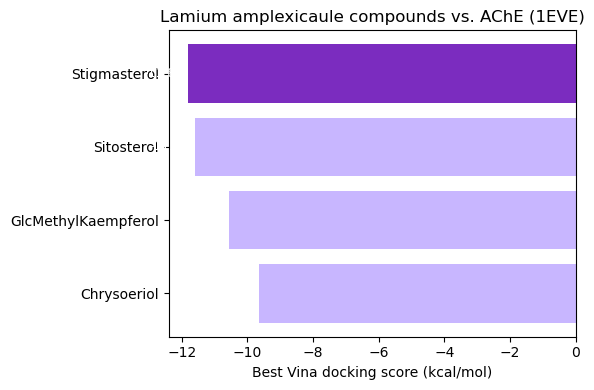

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/lamium_amplexicaule_vs_AChE_scores.png


In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#7b2cbf' if s == docking_df_amplexicaule_AChE['Best_Vina_Score_kcal_mol'].min() else '#c8b6ff'
          for s in docking_df_amplexicaule_AChE['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_amplexicaule_AChE['Compound'], docking_df_amplexicaule_AChE['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Lamium amplexicaule compounds vs. AChE (1EVE)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_amplexicaule_AChE['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')
plt.tight_layout()

fig_path_amplexicaule_AChE = os.path.join(FIGURES_DIR, 'lamium_amplexicaule_vs_AChE_scores.png')
plt.savefig(fig_path_amplexicaule_AChE, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_amplexicaule_AChE)


### 7.8. ProLif interaction fingerprints -- Lamium_amplexicaule vs AChE (each compound, own cell)

`prot_fp` is built once here and reused by every compound's fingerprint cell below.

In [18]:
prot_fp = mda.Universe("1EVE_clean_H_fix.pdb")  # fix_protein() output
prot_fp = plf.Molecule.from_mda(prot_fp)


In [19]:
# ---- ProLif: Chrysoeriol ----
lig_suppl_Chrysoeriol = list(plf.sdf_supplier(vina_out_sdf_Chrysoeriol))
fp_Chrysoeriol = plf.Fingerprint()
fp_Chrysoeriol.run_from_iterable(lig_suppl_Chrysoeriol, prot_fp, n_jobs=1)
results_df_Chrysoeriol = fp_Chrysoeriol.to_dataframe()

print("=== Chrysoeriol ===")
display(results_df_Chrysoeriol)

net_Chrysoeriol = fp_Chrysoeriol.plot_lignetwork(lig_suppl_Chrysoeriol[0], kind="frame", frame=0, rotation=270)
net_html_Chrysoeriol = os.path.join(FIGURES_DIR, "Chrysoeriol_1EVE_2Dnetwork.html")
net_Chrysoeriol.save(net_html_Chrysoeriol)
print("Saved network figure:", net_html_Chrysoeriol)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Chrysoeriol ===


ligand            UNL1                                                       
protein        ASP72.A    PRO86.A   TYR121.A   SER122.A   TYR130.A   SER200.A
interaction VdWContact VdWContact VdWContact VdWContact VdWContact VdWContact
Frame                                                                        
0                False       True       True       True       True      False
1                 True      False       True      False       True      False
2                False      False       True       True      False      False
3                False      False      False       True      False      False
4                False      False      False      False      False      False
5                False      False      False      False      False       True
6                False      False      False      False      False       True
7                False      False      False      False      False      False
8                False      False      False      False      False       True
9                False      False      False      False      False      False

Saved network figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/Chrysoeriol_1EVE_2Dnetwork.html


In [20]:
# ---- ProLif: Stigmasterol ----
lig_suppl_Stigmasterol = list(plf.sdf_supplier(vina_out_sdf_Stigmasterol))
fp_Stigmasterol = plf.Fingerprint()
fp_Stigmasterol.run_from_iterable(lig_suppl_Stigmasterol, prot_fp, n_jobs=1)
results_df_Stigmasterol = fp_Stigmasterol.to_dataframe()

print("=== Stigmasterol ===")
display(results_df_Stigmasterol)

net_Stigmasterol = fp_Stigmasterol.plot_lignetwork(lig_suppl_Stigmasterol[0], kind="frame", frame=0, rotation=270)
net_html_Stigmasterol = os.path.join(FIGURES_DIR, "Stigmasterol_1EVE_2Dnetwork.html")
net_Stigmasterol.save(net_html_Stigmasterol)
print("Saved network figure:", net_html_Stigmasterol)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Stigmasterol ===


ligand            UNL1                                            
protein        ASP72.A   TYR121.A   SER122.A   TRP279.A   PHE331.A
interaction VdWContact VdWContact VdWContact VdWContact VdWContact
Frame                                                             
0                False      False      False      False      False
1                False      False      False      False      False
2                False      False      False      False      False
3                False      False      False      False      False
4                False      False      False      False      False
5                False       True       True       True      False
6                False       True      False      False       True
7                False      False      False      False       True
8                False      False      False      False      False
9                 True      False      False       True      False

KeyError: "None of ['ligand', 'protein', 'interaction', 'atoms'] are in the columns"

In [ ]:
# ---- ProLif: GlcMethylKaempferol ----
lig_suppl_GlcMethylKaempferol = list(plf.sdf_supplier(vina_out_sdf_GlcMethylKaempferol))
fp_GlcMethylKaempferol = plf.Fingerprint()
fp_GlcMethylKaempferol.run_from_iterable(lig_suppl_GlcMethylKaempferol, prot_fp, n_jobs=1)
results_df_GlcMethylKaempferol = fp_GlcMethylKaempferol.to_dataframe()

print("=== GlcMethylKaempferol ===")
display(results_df_GlcMethylKaempferol)

net_GlcMethylKaempferol = fp_GlcMethylKaempferol.plot_lignetwork(lig_suppl_GlcMethylKaempferol[0], kind="frame", frame=0, rotation=270)
net_html_GlcMethylKaempferol = os.path.join(FIGURES_DIR, "GlcMethylKaempferol_1EVE_2Dnetwork.html")
net_GlcMethylKaempferol.save(net_html_GlcMethylKaempferol)
print("Saved network figure:", net_html_GlcMethylKaempferol)


In [ ]:
# ---- ProLif: Sitosterol ----
lig_suppl_Sitosterol = list(plf.sdf_supplier(vina_out_sdf_Sitosterol))
fp_Sitosterol = plf.Fingerprint()
fp_Sitosterol.run_from_iterable(lig_suppl_Sitosterol, prot_fp, n_jobs=1)
results_df_Sitosterol = fp_Sitosterol.to_dataframe()

print("=== Sitosterol ===")
display(results_df_Sitosterol)

net_Sitosterol = fp_Sitosterol.plot_lignetwork(lig_suppl_Sitosterol[0], kind="frame", frame=0, rotation=270)
net_html_Sitosterol = os.path.join(FIGURES_DIR, "Sitosterol_1EVE_2Dnetwork.html")
net_Sitosterol.save(net_html_Sitosterol)
print("Saved network figure:", net_html_Sitosterol)


### 7.9. Figure -- best-scoring compound vs. the real native ligand (E20/donepezil)

In [ ]:
best_row_amplexicaule_AChE = docking_df_amplexicaule_AChE.iloc[0]
best_compound_amplexicaule_AChE = best_row_amplexicaule_AChE['Compound']
print("Best-scoring compound:", best_compound_amplexicaule_AChE, "|", best_row_amplexicaule_AChE['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_amplexicaule_AChE = {
    "Chrysoeriol":         vina_out_sdf_Chrysoeriol,
    "Stigmasterol":        vina_out_sdf_Stigmasterol,
    "GlcMethylKaempferol": vina_out_sdf_GlcMethylKaempferol,
    "Sitosterol":          vina_out_sdf_Sitosterol,
}[best_compound_amplexicaule_AChE]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_amp_AChE = Chem.SDMolSupplier(best_sdf_amplexicaule_AChE)
p_amp_AChE = Chem.MolToMolBlock(results_amp_AChE[0], False)
print('Reference (E20/donepezil): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_amp_AChE[0].GetProp('Pose'), results_amp_AChE[0].GetProp('Score')))

view.addModel(p_amp_AChE, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
